<a href="https://colab.research.google.com/github/maureljean55/atelier-saint-honore/blob/main/q6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict

clients = pd.read_csv("sample_data/client_propre.csv")
y = (clients["est_revenu_6m"] == 0)
cv = StratifiedKFold(5, shuffle=True, random_state=42)

print("clients :", clients.shape)
print(" clients qui ne reviennent pas :", round(y.mean() * 100, 1), "%")

clients : (679, 13)
Part de clients qui ne reviennent pas : 59.1 %


In [4]:
appels_max_mois = 24 * 40
part_max_pct = appels_max_mois / 6400 * 100
nb_cible_fichier = round(len(clients) * part_max_pct / 100)

print("Capacité totale :", appels_max_mois, "appels/mois sur 6 400 clients =", round(part_max_pct, 1), "%")
print("Équivalent sur le fichier de clients :", nb_cible_fichier, "clients max")

Capacité totale : 960 appels/mois sur 6 400 clients = 15.0 %
Équivalent sur notre fichier de 679 clients : 102 clients max


In [5]:
X_2 = clients[["anciennete_mois", "nb_achats_12m"]]
modele_2 = make_pipeline(StandardScaler(), KNeighborsClassifier(21))
probas_2 = cross_val_predict(modele_2, X_2, y, cv=cv, method="predict_proba")[:, 1]

lignes_2 = []
for s in [0.50, 0.65, 0.70, 0.75, 0.80]:
    appeles = probas_2 >= s
    nb = appeles.sum()
    vrais = (appeles & y).sum()
    faux = (appeles & (~y)).sum()
    lignes_2.append({
        "seuil": s,
        "appeles": nb,
        "part_pct": round(nb / len(clients) * 100, 1),
        "precision_pct": round(vrais / nb * 100, 1),
        "rappel_pct": round(vrais / y.sum() * 100, 1),
        "appeles_pour_rien": faux
    })

pd.DataFrame(lignes_2)

,seuil,appeles,part_pct,precision_pct,rappel_pct,appeles_pour_rien
0,0.50,491,72.3,65.2,79.8,171
1,0.65,274,40.4,66.8,45.6,91
2,0.70,188,27.7,67.0,31.4,62
3,0.75,112,16.5,64.3,18.0,40
4,0.80,63,9.3,65.1,10.2,22


In [6]:
cols = ["anciennete_mois", "nb_achats_12m", "panier_moyen_eur", "retours", "demandes_sav"]
X = clients[cols]

resultats = []
for k in [5, 11, 21, 31, 41, 51]:
    modele = make_pipeline(StandardScaler(), KNeighborsClassifier(k))
    scores = cross_val_score(modele, X, y, cv=cv)
    probas_k = cross_val_predict(modele, X, y, cv=cv, method="predict_proba")[:, 1]
    top = pd.DataFrame({"proba": probas_k, "parti": y}).sort_values("proba", ascending=False).head(nb_cible_fichier)
    resultats.append({
        "k": k,
        "justesse": round(scores.mean(), 3),
        "ecart_type": round(scores.std(), 3),
        "precision_top_15pct": round(top["parti"].mean() * 100, 1)
    })

pd.DataFrame(resultats)

,k,justesse,ecart_type,precision_top_15pct
0,5,0.549,0.051,62.7
1,11,0.579,0.049,69.6
2,21,0.602,0.048,69.6
3,31,0.616,0.029,71.6
4,41,0.624,0.032,73.5
5,51,0.626,0.048,68.6


In [7]:
modele_q6 = make_pipeline(StandardScaler(), KNeighborsClassifier(41))
probas = cross_val_predict(modele_q6, X, y, cv=cv, method="predict_proba")[:, 1]

pd.Series(probas).describe().round(3)

,0
count,679.000
mean,0.589
std,0.127
min,0.171
25%,0.488
50%,0.610
75%,0.683
max,0.854


In [8]:
seuils = [0.50, 0.60, 0.65, 0.70, 0.725, 0.75, 0.80]
lignes = []

for s in seuils:
    appeles = probas >= s
    nb = appeles.sum()
    vrais = (appeles & y).sum()
    faux = (appeles & (~y)).sum()
    lignes.append({
        "seuil": s,
        "clients_appeles": nb,
        "part_base_pct": round(nb / len(clients) * 100, 1),
        "appels_par_boutique": round(nb / len(clients) * (6400 / 24), 1),
        "vrais_departs": vrais,
        "appeles_pour_rien": faux,
        "precision_pct": round(vrais / nb * 100, 1),
        "rappel_pct": round(vrais / y.sum() * 100, 1)
    })

table_seuils = pd.DataFrame(lignes)
table_seuils

,seuil,clients_appeles,part_base_pct,appels_par_boutique,vrais_departs,appeles_pour_rien,precision_pct,rappel_pct
0,0.500,508,74.8,199.5,327,181,64.4,81.5
1,0.600,384,56.6,150.8,255,129,66.4,63.6
2,0.650,286,42.1,112.3,193,93,67.5,48.1
3,0.700,137,20.2,53.8,98,39,71.5,24.4
4,0.725,92,13.5,36.1,67,25,72.8,16.7
5,0.750,43,6.3,16.9,34,9,79.1,8.5
6,0.800,8,1.2,3.1,7,1,87.5,1.7


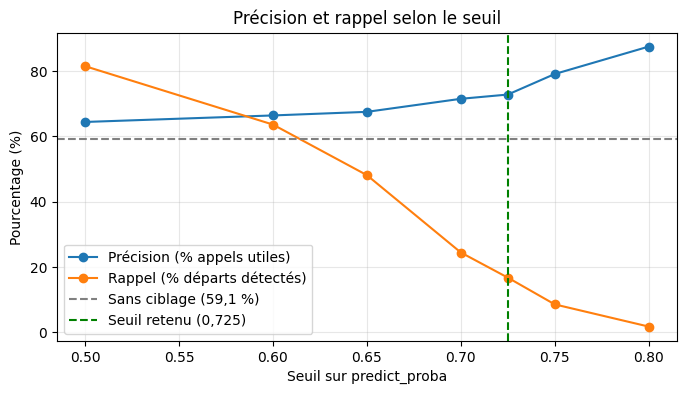

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(table_seuils["seuil"], table_seuils["precision_pct"], marker="o", label="Précision (% appels utiles)")
plt.plot(table_seuils["seuil"], table_seuils["rappel_pct"], marker="o", label="Rappel (% départs détectés)")
plt.axhline(y.mean() * 100, color="gray", linestyle="--", label="Sans ciblage (59,1 %)")
plt.axvline(0.725, color="green", linestyle="--", label="Seuil retenu (0,725)")
plt.xlabel("Seuil sur predict_proba")
plt.ylabel("Pourcentage (%)")
plt.title("Précision et rappel selon le seuil")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

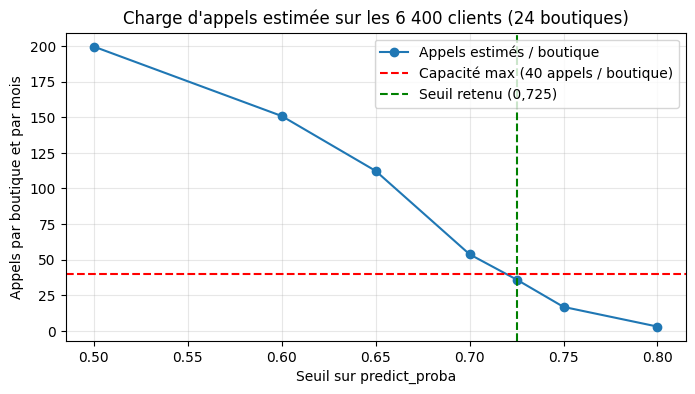

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(table_seuils["seuil"], table_seuils["appels_par_boutique"], marker="o", label="Appels estimés / boutique")
plt.axhline(40, color="red", linestyle="--", label="Capacité max (40 appels / boutique)")
plt.axvline(0.725, color="green", linestyle="--", label="Seuil retenu (0,725)")
plt.xlabel("Seuil sur predict_proba")
plt.ylabel("Appels par boutique et par mois")
plt.title("Charge d'appels estimée sur les 6 400 clients (24 boutiques)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
appeles_retenu = probas >= 0.725

pd.crosstab(y, appeles_retenu, rownames=["Réel (parti)"], colnames=["Appelé (seuil >= 0,725)"])

"Appelé (seuil >= 0,725)",False,True
Réel (parti),,
False,253,25
True,334,67


In [12]:
clients["a_appeler"] = probas >= 0.725

clients.groupby("a_appeler")[cols + ["montant_total_eur"]].mean().round(1)

,anciennete_mois,nb_achats_12m,panier_moyen_eur,retours,demandes_sav,montant_total_eur
a_appeler,,,,,,
False,33.2,3.9,2799.2,0.5,0.3,14068.7
True,16.2,2.2,1646.7,0.5,0.8,3587.2


In [13]:
clients.groupby("a_appeler")[cols + ["montant_total_eur"]].median().round(1)

,anciennete_mois,nb_achats_12m,panier_moyen_eur,retours,demandes_sav,montant_total_eur
a_appeler,,,,,,
False,25.0,3.0,2213.0,0.0,0.0,5727.0
True,13.0,2.0,1530.0,0.0,1.0,2766.5


In [14]:
clients[clients["a_appeler"]]["carte_fidelite"].value_counts()

,count
carte_fidelite,
aucune,45
argent,34
or,13


In [15]:
modele_final = make_pipeline(StandardScaler(), KNeighborsClassifier(41)).fit(X, y)
clients["proba_depart"] = modele_final.predict_proba(X)[:, 1].round(3)

liste_appels = clients[clients["proba_depart"] >= 0.725].sort_values(
    ["proba_depart", "panier_moyen_eur"], ascending=[False, False]
)

print("Clients à appeler (>= 0,725) :", len(liste_appels), f"({round(len(liste_appels)/len(clients)*100, 1)} %)")
liste_appels[["client_id", "boutique_principale", "anciennete_mois", "nb_achats_12m", "panier_moyen_eur", "demandes_sav", "proba_depart"]].head(15)

Clients à appeler (>= 0,725) : 82 (12.1 %)


,client_id,boutique_principale,anciennete_mois,nb_achats_12m,panier_moyen_eur,demandes_sav,proba_depart
491,CT80406,BT10,1,2,1444.0,1,0.854
76,CT80408,BT22,1,1,2344.0,1,0.829
309,CT80430,BT12,7,1,2229.0,1,0.829
657,CT80044,BT25,12,1,2126.0,1,0.829
417,CT80653,BT19,7,2,2028.0,1,0.829
297,CT80240,BT16,18,2,1317.0,1,0.829
123,CT80299,BT13,1,3,1143.0,1,0.829
29,CT80034,BT31,20,3,1499.0,1,0.805
163,CT80467,BT31,1,3,1473.0,1,0.805
69,CT80285,BT10,9,2,1360.0,1,0.805


In [16]:
liste_appels.groupby("boutique_principale").agg(
    nb_clients=("client_id", "count"),
    proba_moyenne=("proba_depart", "mean"),
    panier_moyen=("panier_moyen_eur", "mean")
).round(2).sort_values("nb_clients", ascending=False).head(10)

,nb_clients,proba_moyenne,panier_moyen
boutique_principale,,,
BT15,7,0.75,1625.00
BT10,6,0.79,1535.67
BT32,6,0.75,2139.83
BT30,5,0.76,1300.60
BT31,5,0.78,1453.80
BT12,5,0.77,1688.40
BT14,4,0.76,1567.50
BT27,4,0.76,1845.50
BT22,4,0.79,1965.00
